In [1]:
import sys

In [2]:
import matplotlib.pyplot as plt

sys.path.append("..")
from wavelet_transform.utils.save_plots import save_figure

import matplotlib.pyplot as plt
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.kmeans_results as results

In [3]:
# Get bubble dynamics results
R_init = 100e-6
frequency = 1e6
pac = -2e6
result_id = f"{R_init}_{frequency}_{pac}"

# # Get PCD results
# voltage = 120
# pcd_number = 10
# result_id = f"{voltage}_{pcd_number}"

In [4]:
data_train, tr_obj, centers, labels, sampling_rate, freq_threshold = results.get_data(result_id)
classifying_metrics = data_train.columns.to_list()

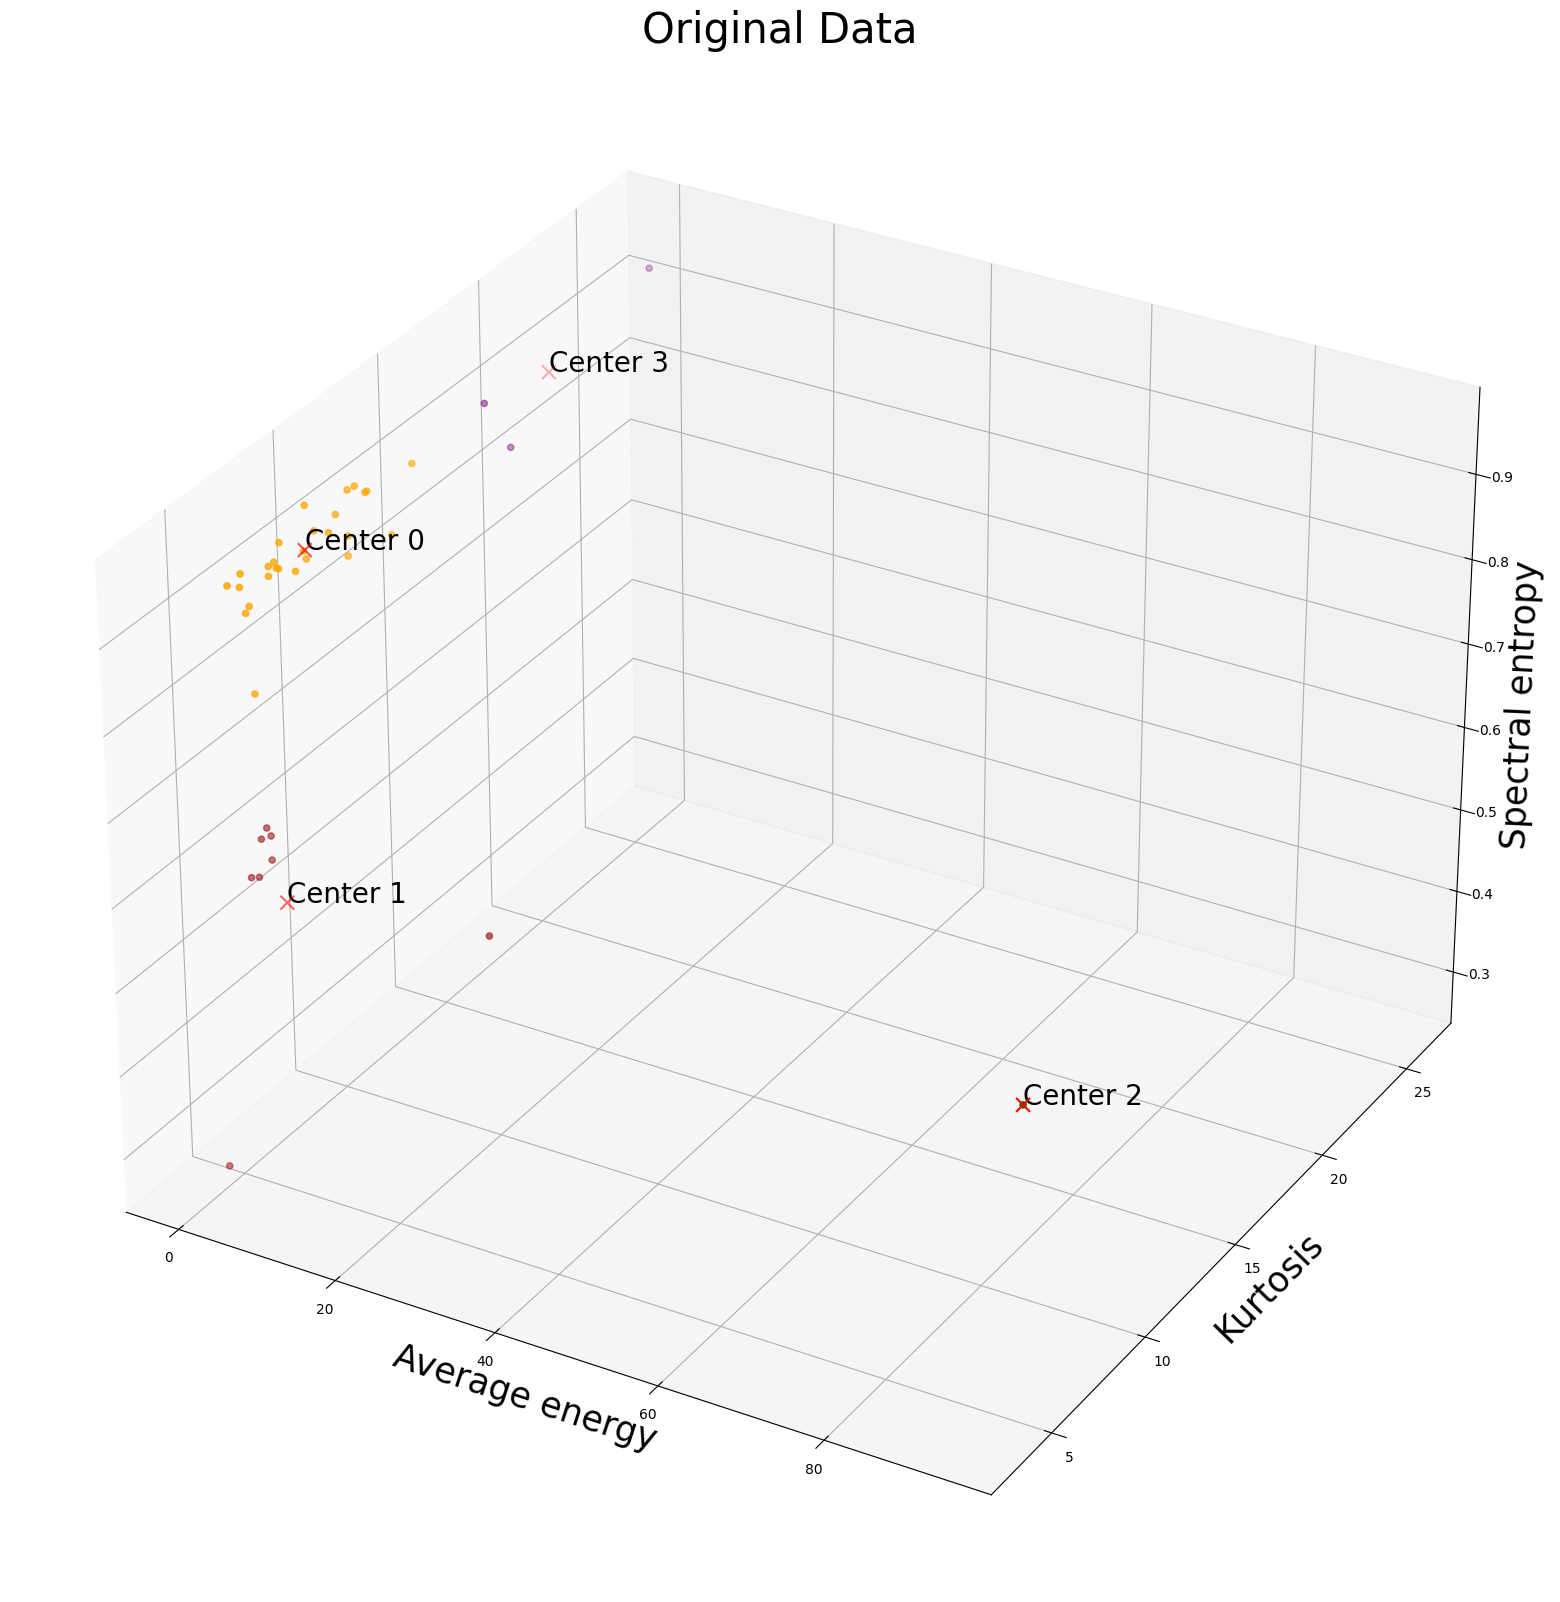

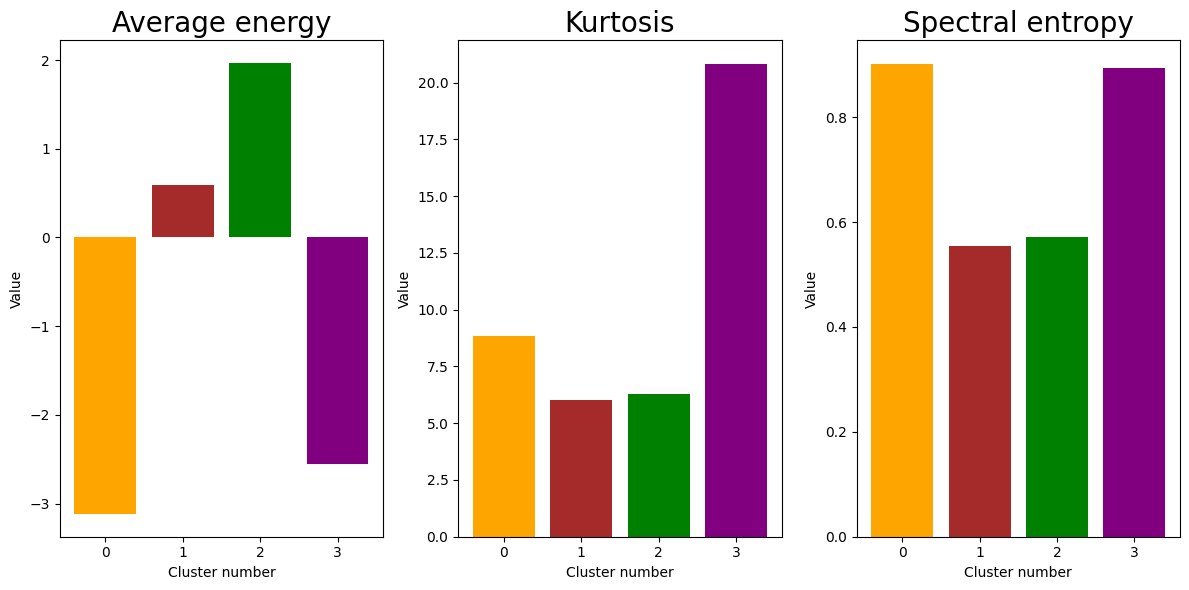

In [5]:
fig = plot.plot_clustering(data_train, centers, labels)

save_figure(fig, f"clustering_{result_id}")

# Plot centroid metrics
fig = plot.plot_centers(classifying_metrics, centers)

save_figure(fig, f"centroids_{result_id}")

In [6]:
# Set clusters to None to plot all of them, otherwise, plot a list of int
fig = plot.plot_fft_by_group(
    tr_obj, labels, no_clusters=None, sampling_rate=sampling_rate,
    clusters=None, xlim=10, fundamental_freq=frequency,
    freq_threshold=freq_threshold
)

fig = plot.plot_reconstructions_by_group(
    tr_obj, labels, no_clusters=None, t_plot=sampling_rate, freq_threshold=freq_threshold
)